In [1]:
'''Visualize decision boundaries for classifiers in multi-dimensional space, using techniques such as PCA or t-SNE for 
dimensionality reduction to interpret model behavior and identify areas of uncertainty.'''

'Visualize decision boundaries for classifiers in multi-dimensional space, using techniques such as PCA or t-SNE for \ndimensionality reduction to interpret model behavior and identify areas of uncertainty.'

In [2]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [3]:
# loading dataset
df = pd.read_csv('global_pharmacy_sales_data.csv')
df.head()

,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0


In [4]:
# inspecting dataset summary and info
print(df.shape)
print(df.describe())

(177990, 14)
                year          month            day     units_sold  \
count  177990.000000  177990.000000  177990.000000  177990.000000   
mean     2022.499702       6.521754      15.730457     447.913849   
std         1.708113       3.448703       8.801170     338.924528   
min      2020.000000       1.000000       1.000000      31.000000   
25%      2021.000000       4.000000       8.000000     284.000000   
50%      2023.000000       7.000000      16.000000     387.000000   
75%      2024.000000      10.000000      23.000000     529.000000   
max      2025.000000      12.000000      31.000000    8704.000000   

          unit_price    stock_level  expiry_days_remaining     covid_flag  
count  177990.000000  177990.000000          177990.000000  177990.000000  
mean       52.554729    4552.991780             374.038109       0.333519  
std        27.421909     346.608511             199.759193       0.471471  
min         5.000000       0.000000              30.000000   

In [5]:
# preparing features and binary classification target
df['high_sales'] = (df['units_sold'] >= df['units_sold'].median()).astype(int)
features = ['unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag', 'month']
sample_df = df.sample(n=2000, random_state=42).reset_index(drop=True)
X = sample_df[features]
y = sample_df['high_sales']
print(X.head())
print(y.value_counts())

   unit_price  stock_level  expiry_days_remaining  covid_flag  month
0       53.07         4601                    342           0     11
1       79.53         4696                    524           0      7
2       49.82         4352                    677           0      5
3       64.46         4603                    198           1      9
4       87.59         4515                    224           0      7
high_sales
1    1008
0     992
Name: count, dtype: int64


In [6]:
# standardizing feature data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled[:3])

[[ 0.04112253  0.1518067  -0.16592409 -0.70816771  1.33128478]
 [ 1.02651254  0.411532    0.75605933 -0.70816771  0.17289037]
 [-0.07990988 -0.52894697  1.5311333  -0.70816771 -0.40630684]]


In [7]:
# applying pca for dimensionality reduction to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('explained variance ratio:', pca.explained_variance_ratio_)

explained variance ratio: [0.27368918 0.20663388]


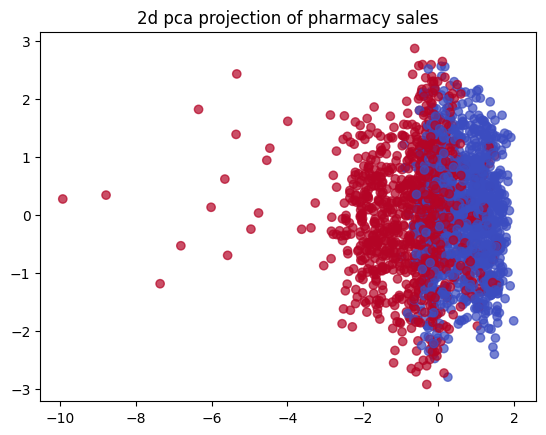

In [8]:
# plotting 2d pca feature representation
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', alpha=0.7)
plt.title('2d pca projection of pharmacy sales')
plt.show()

In [9]:
# training classifier on reduced 2d pca space
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.25, random_state=42)
clf = LogisticRegression()
clf.fit(X_train, y_train)
print('training accuracy:', accuracy_score(y_train, clf.predict(X_train)))
print('testing accuracy:', accuracy_score(y_test, clf.predict(X_test)))

training accuracy: 0.8173333333333334
testing accuracy: 0.818


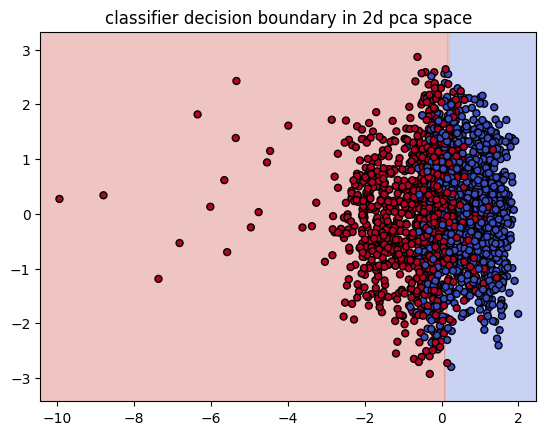

In [10]:
# visualizing decision boundary for classifier
x_min, x_max = X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5
y_min, y_max = X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=25)
plt.title('classifier decision boundary in 2d pca space')
plt.show()

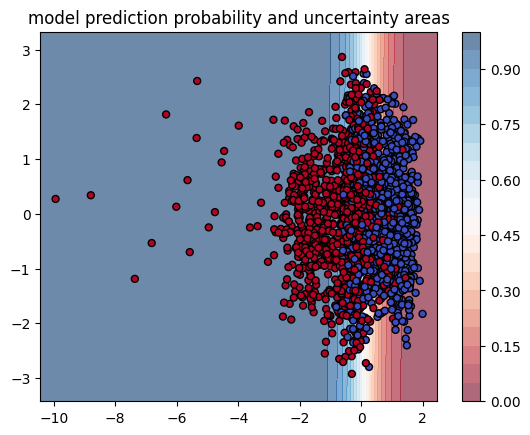

In [11]:
# visualizing areas of model uncertainty using prediction probabilities
probs = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
plt.contourf(xx, yy, probs, levels=20, cmap='RdBu', alpha=0.6)
plt.colorbar()
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=25)
plt.title('model prediction probability and uncertainty areas')
plt.show()

In [12]:
# applying tsne for non linear dimensionality reduction
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_scaled[:500])
y_tsne = y.iloc[:500]
print(X_tsne.shape)

(500, 2)


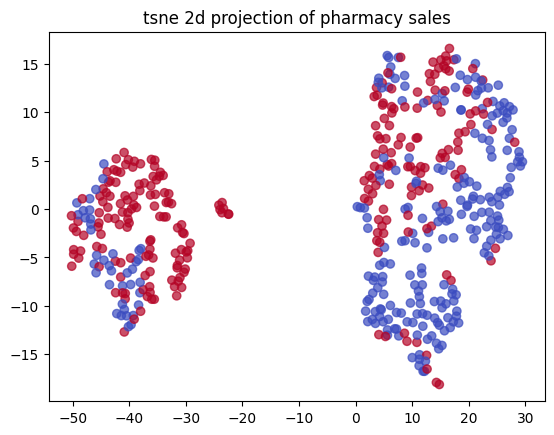

In [13]:
# plotting tsne 2d projection of sales data
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_tsne, cmap='coolwarm', alpha=0.7)
plt.title('tsne 2d projection of pharmacy sales')
plt.show()